# B1: Predict Uber ride fare: preprocess data, identify outliers, check correlation, train Linear Regression and Random Forest Regression, and compare R² and RMSE

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../ML/1-uber.csv')
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [4]:
df.shape

(200000, 9)

In [5]:
df = df.drop(['Unnamed: 0', 'key', 'pickup_datetime'], axis=1)
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1


In [6]:
df.isnull().sum()

fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [7]:
df = df.dropna()
df.isnull().sum()

fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [8]:
import numpy as np
def dist(lat1, lon1, lat2, lon2):
    distance = (lat1-lat2)**2 + (lon1-lon2)**2
    distance = np.sqrt(distance)
    return distance

df['distance'] = dist(df['pickup_latitude'], df['pickup_longitude'], df['dropoff_latitude'], df['dropoff_longitude'])
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,0.015140
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,0.022103
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,0.053109
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,0.016528
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,0.051031
...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,0.001064
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,0.022126
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,0.142223
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1,0.033101


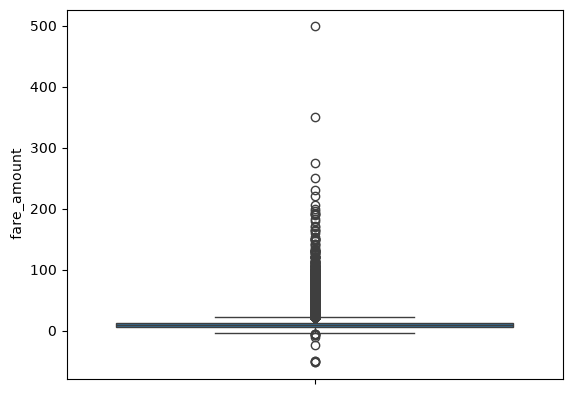

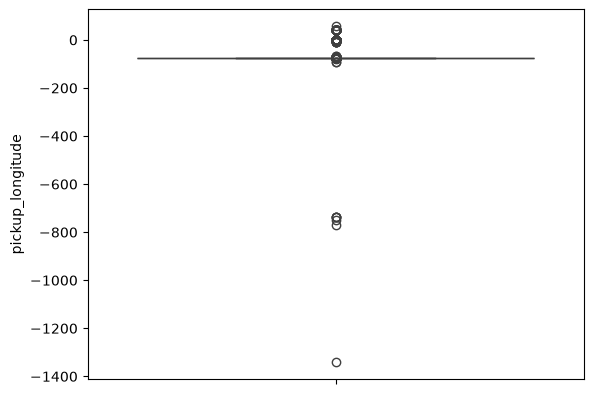

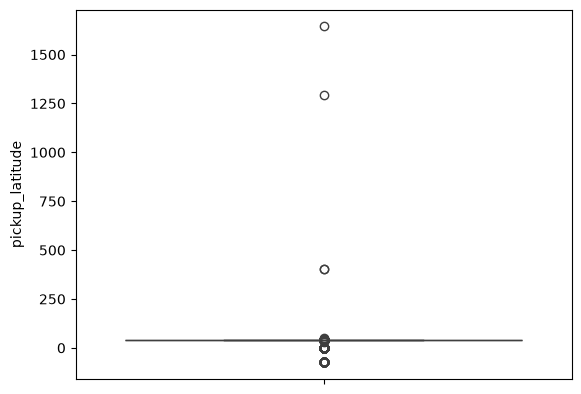

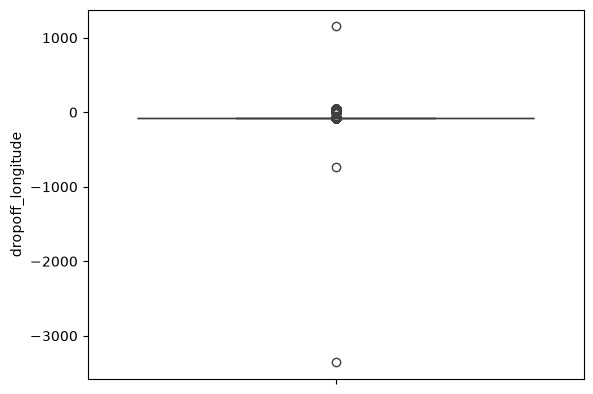

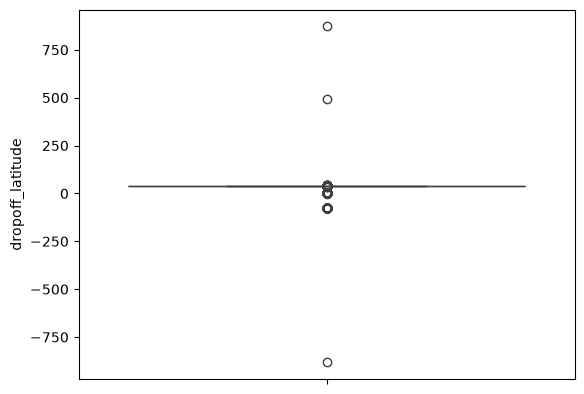

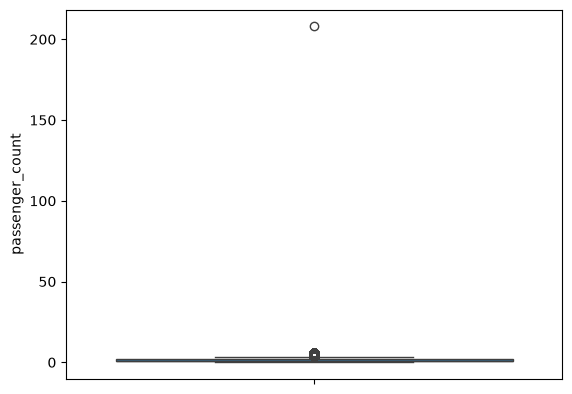

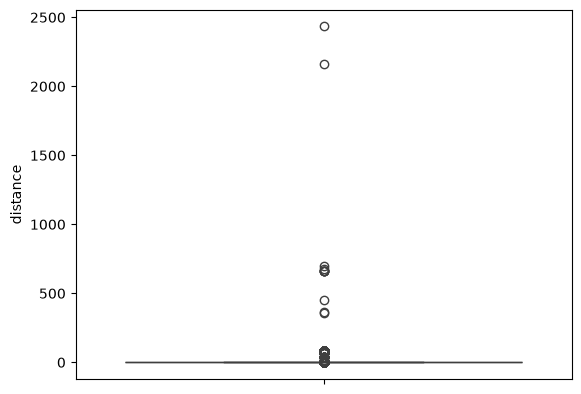

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in df:
    sns.boxplot(data=df[col])
    plt.show()

Number of outliers in column fare_amount: 17166


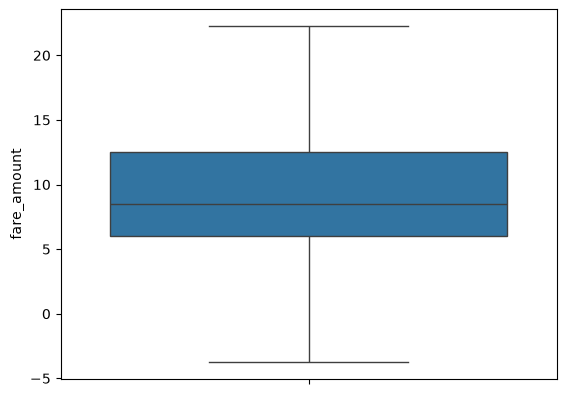

Number of outliers in column pickup_longitude: 13559


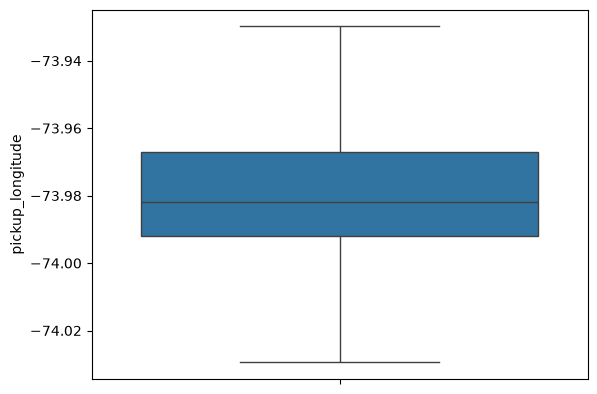

Number of outliers in column pickup_latitude: 9423


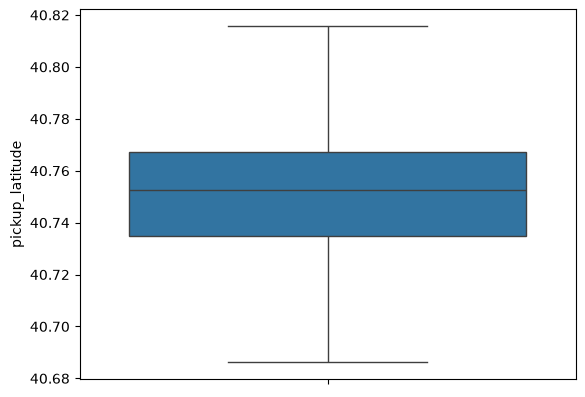

Number of outliers in column dropoff_longitude: 14200


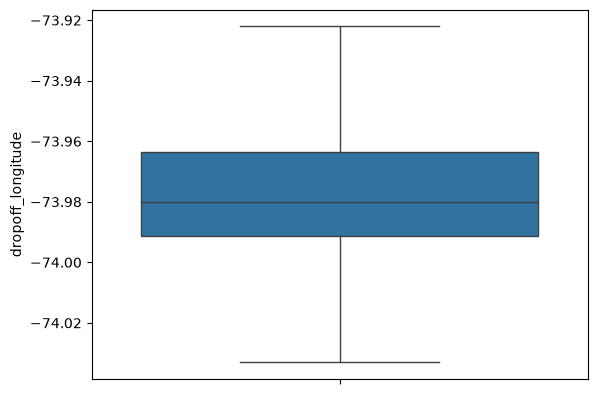

Number of outliers in column dropoff_latitude: 12145


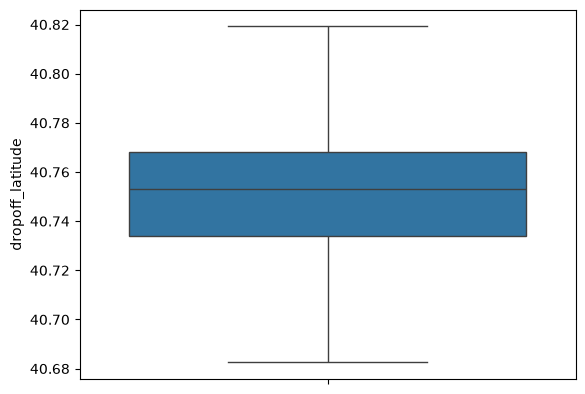

Number of outliers in column passenger_count: 22557


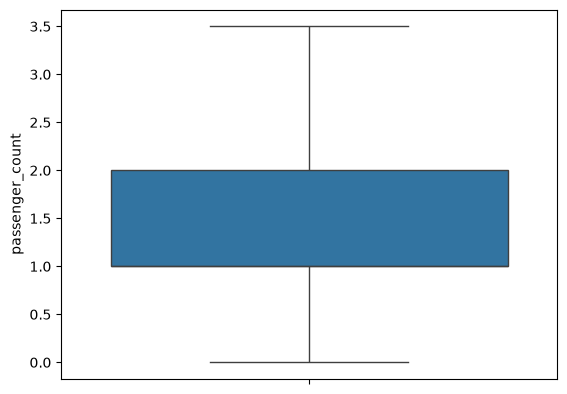

Number of outliers in column distance: 17344


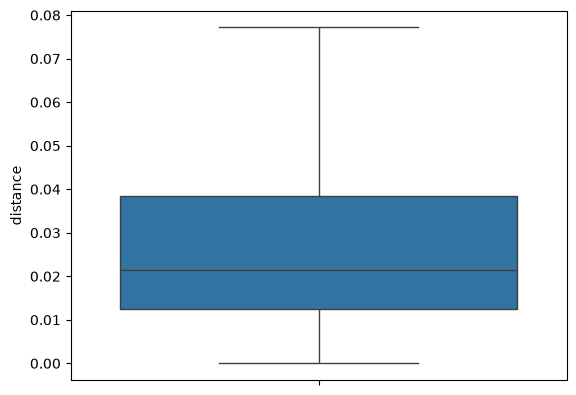

In [10]:
for col in df:
    q3 = df[col].quantile(0.75)
    q1 = df[col].quantile(0.25)
    iqr = q3-q1
    lb = q1-1.5*iqr
    ub = q3+1.5*iqr
    print(f"Number of outliers in column {col}: {len(df)-len(df[(df[col] >= lb) & (df[col] <= ub)])}")
    # df = df[(df[col] >= lb) & (df[col] <= ub)]
    df[col] = df[col].clip(lb, ub)
    sns.boxplot(data=df[col])
    plt.show()

In [11]:
X = df.drop(['fare_amount'], axis=1)
y = df['fare_amount']
display(X)
display(y)

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,-73.999817,40.738354,-73.999512,40.723217,1.0,0.015140
1,-73.994355,40.728225,-73.994710,40.750325,1.0,0.022103
2,-74.005043,40.740770,-73.962565,40.772647,1.0,0.053109
3,-73.976124,40.790844,-73.965316,40.803349,3.0,0.016528
4,-73.929788,40.744085,-73.973082,40.761247,3.5,0.051031
...,...,...,...,...,...,...
199995,-73.987042,40.739367,-73.986525,40.740297,1.0,0.001064
199996,-73.984722,40.736837,-74.006672,40.739620,1.0,0.022126
199997,-73.986017,40.756487,-73.922036,40.692588,2.0,0.077190
199998,-73.997124,40.725452,-73.983215,40.695415,1.0,0.033101


0          7.50
1          7.70
2         12.90
3          5.30
4         16.00
          ...  
199995     3.00
199996     7.50
199997    22.25
199998    14.50
199999    14.10
Name: fare_amount, Length: 199999, dtype: float64

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
df.corr()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
fare_amount,1.000000,0.154053,-0.110857,0.218681,-0.125874,0.015798,0.845112
pickup_longitude,0.154053,1.000000,0.259496,0.425622,0.073313,-0.013202,0.107350
pickup_latitude,-0.110857,0.259496,1.000000,0.048887,0.515736,-0.012879,-0.042654
dropoff_longitude,0.218681,0.425622,0.048887,1.000000,0.245670,-0.009304,0.204677
dropoff_latitude,-0.125874,0.073313,0.515736,0.245670,1.000000,-0.006329,-0.034068
passenger_count,0.015798,-0.013202,-0.012879,-0.009304,-0.006329,1.000000,0.008890
distance,0.845112,0.107350,-0.042654,0.204677,-0.034068,0.008890,1.000000


<Axes: >

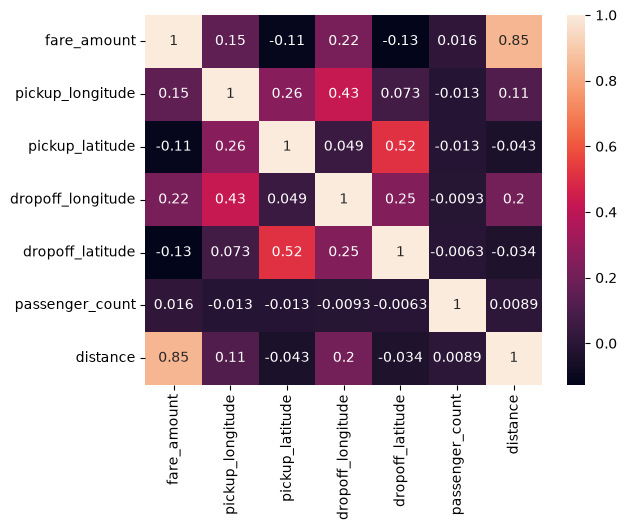

In [15]:
sns.heatmap(data=df.corr(), annot=True)

In [16]:
from sklearn.linear_model import LinearRegression
linear = LinearRegression()

linear.fit(X_train_scaled, y_train)

y_pred = linear.predict(X_test_scaled)

In [17]:
from sklearn.metrics import r2_score, root_mean_squared_error

r2 = r2_score(y_true=y_test, y_pred=y_pred)
rmse = root_mean_squared_error(y_true=y_test, y_pred=y_pred)
print(f"R2 Score = {r2}")
print(f"RMSE Score = {rmse}")

R2 Score = 0.7171506167931101
RMSE Score = 2.8966758165962005


In [18]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor()

rf.fit(X_train_scaled, y_train)

y_pref = rf.predict(X_test_scaled)


In [19]:
r2 = r2_score(y_true=y_test, y_pred=y_pref)
rmse = root_mean_squared_error(y_true=y_test, y_pred=y_pref)
print(f"R2 Score = {r2}")
print(f"RMSE Score = {rmse}")

R2 Score = 0.7622154210957698
RMSE Score = 2.6559146740860435
